# 01.1 · Gene-body counts (exons + introns) with featureCounts

**Why.** Our G&T input is **nuclei**. A nucleus holds little mature mRNA (that is exported to the cytoplasm);
most of its RNA is pre-mRNA, i.e. mostly intron. BJ-Expression is built for whole cells and counts **exons only**
(HTSeq on exons, Salmon on spliced transcripts), so in our good nuclei 55–80% of the reads are thrown away
and we detect 2–4× fewer genes than we could.

**What this notebook does.** BJ-Expression already aligned every read to the genome with STAR, so the intronic
reads are in its BAMs. We only **re-count** those BAMs on whole gene bodies — no re-alignment.

1. get `featureCounts` (Subread prebuilt binary)
2. get the GTF matching the pipeline: GENCODE v38 = Ensembl 104 (what BJ-Expression used),
   with `chr1`-style names (like the BAMs) and versioned gene IDs (like the HTSeq matrix)
3. run `featureCounts` on gene bodies
4. check the result against the exon-only HTSeq matrix

**Output:** `counts_genebody.txt` (genes × BAMs) + `.summary`, loaded in `02_RNA_DNA_QC.ipynb` as layer `genebody_counts`.

**Resources:** ~1–2 GB RAM, a few minutes with 16 threads, output < 50 MB.

## 0. Paths and settings

In [10]:
import os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
# ---- tool: Subread, compiled from source (the prebuilt binary segfaults on this VM) ----
TOOLS_DIR       = "/home/gdallagl/myworkdir/tools"
SUBREAD_VERSION = "2.0.6"
FEATURECOUNTS   = f"{TOOLS_DIR}/subread-{SUBREAD_VERSION}-source/bin/featureCounts"

# ---- annotation: GENCODE v38 = Ensembl 104, the release used by BJ-Expression ----
GTF_DIR = "/home/gdallagl/myworkdir/XDP/data/gencode/v38"
GTF_URL = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/gencode.v38.annotation.gtf.gz"
GTF     = f"{GTF_DIR}/gencode.v38.annotation.gtf.gz"

# ---- inputs: BJ-Expression results ----
RNA_RES   = "/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/results_BJ-Expression"
BAM_DIR   = f"{RNA_RES}/secondary_analyses/alignment_htseq"                                  # STAR BAMs, full depth
HTSEQ     = f"{RNA_RES}/secondary_analyses/quantification_htseq/matrix_gene_counts_starhtseq.txt"  # exon-only, for comparison
PLATE_MAP = "/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/XDP_GandT_plate_map_cells.csv"

# ---- featureCounts settings ----
N_THREADS = 16
STRAND    = 0       # full-length (Smart-seq-like) libraries are unstranded

# ---- output ----
OUT_DIR    = "/home/gdallagl/myworkdir/XDP/data/XDP/G_and_T/rna_libs/featurecounts_genebody"
OUT_COUNTS = f"{OUT_DIR}/counts_genebody.txt"

# make the settings visible to the %%bash cells below as $NAME
for name in ["TOOLS_DIR", "SUBREAD_VERSION", "FEATURECOUNTS", "GTF_DIR", "GTF_URL", "GTF",
             "BAM_DIR", "N_THREADS", "STRAND", "OUT_DIR", "OUT_COUNTS"]:
    os.environ[name] = str(globals()[name])

In [12]:
# plate map: RNA well -> cell_id (same helper as in 02_RNA_DNA_QC)
plate = pd.read_csv(PLATE_MAP).set_index("cell_id")
RNA_WELL_TO_CELL = pd.Series(plate.index, index=plate["rna_well"])


def cell_from_rna(names):
    """'.../2535GJLT4-1-0457512804-G8-RNA.bam' -> RNA well 'G8' -> 'cell_xx'  (NaN if not a cell)"""
    well = pd.Index(names).astype(str).str.extract(r"-([A-P]\d+)-RNA")[0]
    return well.map(RNA_WELL_TO_CELL).values

## 1. Get featureCounts

Compiled from the Subread source (needs only `gcc`, `make` and zlib, all on this VM; ~1 min).
The prebuilt Linux binary from SourceForge **segfaults on this VM** even on a tiny test file, so we don't use it.
Skipped if already built.

In [13]:
%%bash
cd "$TOOLS_DIR"
if [ ! -x "$FEATURECOUNTS" ]; then
    wget -q -O subread-src.tar.gz \
        "https://sourceforge.net/projects/subread/files/subread-${SUBREAD_VERSION}/subread-${SUBREAD_VERSION}-source.tar.gz/download"
    tar xzf subread-src.tar.gz
    rm subread-src.tar.gz
    cd "subread-${SUBREAD_VERSION}-source/src"
    make -f Makefile.Linux -j 16 > ../build.log 2>&1      # binaries go to subread-*-source/bin/
fi
"$FEATURECOUNTS" -v


featureCounts v2.0.6



## 2. Get the GTF

GENCODE v38 *primary* annotation (`gencode.v38.annotation.gtf.gz`): genes on the main chromosomes only.
featureCounts reads the `.gz` directly.

A GTF is a map of the genome. It's a plain text table in which each row says "this feature sits on this chromosome, from this position to this position, on this strand". A feature can be a gene, a transcript or an exon. For example:


chr1  HAVANA  gene  11869  14409  .  +  .  gene_id "ENSG00000290825.1"; gene_name "DDX11L2"; ...
chr1  HAVANA  exon  11869  12227  .  +  .  gene_id "ENSG00000290825.1"; ...
GTF stands for Gene Transfer Format.


GENCODE is the project that maintains the human gene annotation. It decides where each gene, exon and transcript is, and publishes that as a GTF. GENCODE and Ensembl produce the same annotation


Why you need it here: your BAMs only say where each read landed, e.g. "read X aligned to chr1 at position 11,950". They say nothing about genes. To get a genes × cells count matrix, featureCounts has to look up each read's position in the GTF:

In [14]:
%%bash
mkdir -p "$GTF_DIR"
[ -f "$GTF" ] || wget -q -O "$GTF" "$GTF_URL"
ls -lh "$GTF"
zcat "$GTF" | grep -v "^#" | head -n 1

-rw-r--r-- 1 gdallagl gdallagl 45M Mar 12  2021 /home/gdallagl/myworkdir/XDP/data/gencode/v38/gencode.v38.annotation.gtf.gz
chr1	HAVANA	gene	11869	14409	.	+	.	gene_id "ENSG00000223972.5"; gene_type "transcribed_unprocessed_pseudogene"; gene_name "DDX11L1"; level 2; hgnc_id "HGNC:37102"; havana_gene "OTTHUMG00000000961.2";


In [15]:
# sanity check: chromosome names must be the same in BAMs and GTF ('chr1' vs '1' would give 0 counts)
bams = sorted(f for f in os.listdir(BAM_DIR) if f.endswith("-RNA.bam"))
bam_chroms = subprocess.run(f"samtools view -H {BAM_DIR}/{bams[0]} | grep '^@SQ' | cut -f2 | sed 's/SN://'",
                            shell=True, capture_output=True, text=True).stdout.split()
gtf_chroms = subprocess.run(f"zcat {GTF} | grep -v '^#' | cut -f1 | uniq | sort -u",
                            shell=True, capture_output=True, text=True).stdout.split()

print(len(bams), "RNA BAMs")
print("GTF chromosomes:", gtf_chroms)
print("GTF chromosomes missing from the BAMs:", sorted(set(gtf_chroms) - set(bam_chroms)))

47 RNA BAMs
GTF chromosomes: ['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrM', 'chrX', 'chrY']
GTF chromosomes missing from the BAMs: []


## 3. Count reads on gene bodies

- `-t gene -g gene_id` : the feature is the whole gene (exons + introns), one count per gene_id
- `-p --countReadPairs` : paired-end; one count per read pair (fragment), not per read
- `-s 0` : unstranded
- `--extraAttributes gene_name` : keep the gene symbol as an extra column
- defaults kept on purpose: multi-mapping reads are **not** counted, and reads overlapping two genes are **not**
  counted (ambiguous) — same rules as HTSeq in BJ-Expression, so the only change is exons → gene bodies

Note: unstranded + gene bodies → reads in introns shared by two genes on opposite strands are ambiguous and dropped.

Runtime: a few minutes. The log goes to `featurecounts.log`.

In [16]:
%%bash
mkdir -p "$OUT_DIR"
"$FEATURECOUNTS" \
    -a "$GTF" \
    -o "$OUT_COUNTS" \
    -t gene -g gene_id \
    --extraAttributes gene_name \
    -p --countReadPairs \
    -s "$STRAND" \
    -T "$N_THREADS" \
    "$BAM_DIR"/*-RNA.bam \
    > "$OUT_DIR/featurecounts.log" 2>&1

tail -n 12 "$OUT_DIR/featurecounts.log"
ls -lh "$OUT_DIR"

||    Successfully assigned alignments : 2503 (1.4%)                          ||
||    Running time : 0.01 minutes                                             ||
||                                                                            ||
|| Write the final count table.                                               ||
|| Write the read assignment summary.                                         ||
||                                                                            ||
|| Summary of counting results can be found in file "/home/gdallagl/myworkdi  ||
|| r/XDP/data/XDP/G_and_T/rna_libs/featurecounts_genebody/counts_genebody.tx  ||
|| t.summary"                                                                 ||
||                                                                            ||
\\============================================================================//

total 9.0M
-rw-r--r-- 1 gdallagl gdallagl 9.0M Nov  5 01:35 counts_genebody.txt
-rw-r--r-- 1 gdallagl gdalla

## 4. Check the result

### 4.1 Where did the read pairs go? (`.summary`)

- `Assigned` : counted in a gene
- `Unassigned_NoFeatures` : outside any gene (intergenic)
- `Unassigned_Ambiguity` : overlaps 2+ genes
- `Unassigned_MultiMapping` : maps to several places

In [17]:
summary = pd.read_csv(f"{OUT_COUNTS}.summary", sep="\t", index_col=0)
summary.columns = cell_from_rna(summary.columns)
summary = summary.loc[summary.sum(axis=1) > 0, pd.notna(summary.columns)].T     # cells x categories (non-empty only)

summary_frac = summary.div(summary.sum(axis=1), axis=0)
display(summary_frac.assign(total_pairs=summary.sum(axis=1)).sort_values("Assigned", ascending=False).round(3))

Status,Assigned,Unassigned_Unmapped,Unassigned_MultiMapping,Unassigned_NoFeatures,Unassigned_Ambiguity,total_pairs
cell_10,0.609,0.218,0.018,0.028,0.127,3070512
cell_12,0.602,0.254,0.021,0.017,0.106,1335652
cell_22,0.583,0.245,0.016,0.029,0.127,18902098
cell_41,0.582,0.252,0.020,0.052,0.094,1780313
cell_42,0.532,0.302,0.019,0.050,0.097,3267911
cell_19,0.529,0.290,0.021,0.033,0.127,6331524
cell_25,0.428,0.428,0.057,0.015,0.073,3710833
cell_13,0.413,0.437,0.037,0.041,0.072,364894
cell_35,0.361,0.443,0.063,0.005,0.128,552920
cell_40,0.352,0.555,0.059,0.008,0.026,3310097


### 4.2 Gene-body vs exon-only (HTSeq) counts, per cell

- gene IDs must match the HTSeq matrix (both Ensembl 104 / GENCODE v38, with version)
- `intronic_frac` = 1 − exon-only counts / gene-body counts
- genes detected = genes with ≥ 1 count

In [18]:
# gene-body counts: genes x cells
fc = pd.read_csv(OUT_COUNTS, sep="\t", comment="#", index_col=0)
gene_names = fc["gene_name"]
genebody = fc.drop(columns=["Chr", "Start", "End", "Strand", "Length", "gene_name"])
genebody.columns = cell_from_rna(genebody.columns)
genebody = genebody.loc[:, pd.notna(genebody.columns)]

# exon-only HTSeq counts: rows 'ENSG..._SYMBOL', drop the '__no_feature'-type summary rows
htseq = pd.read_csv(HTSEQ, sep="\t", index_col=0)
htseq = htseq[~htseq.index.str.startswith("__")]
htseq.index = htseq.index.str.split("_", n=1).str[0]
htseq = htseq.groupby(level=0).sum()
htseq.columns = cell_from_rna(htseq.columns)
htseq = htseq.loc[:, pd.notna(htseq.columns)]

shared = genebody.index.intersection(htseq.index)
print(f"gene-body genes: {len(genebody)} | HTSeq genes: {len(htseq)} | shared IDs: {len(shared)}")

gene-body genes: 60649 | HTSeq genes: 12899 | shared IDs: 12893


In [19]:
cells_ = genebody.columns.intersection(htseq.columns)

compare = pd.DataFrame({
    "pairs_genebody": genebody[cells_].sum(),
    "counts_exon":    htseq[cells_].sum(),
    "genes_genebody": (genebody[cells_] > 0).sum(),
    "genes_exon":     (htseq[cells_] > 0).sum(),
})
compare["intronic_frac"] = 1 - compare["counts_exon"] / compare["pairs_genebody"].replace(0, np.nan)
compare["gene_gain"]     = compare["genes_genebody"] / compare["genes_exon"].replace(0, np.nan)
compare = compare[compare["pairs_genebody"] > 0].sort_values("genes_genebody", ascending=False)
display(compare.round(2))

,pairs_genebody,counts_exon,genes_genebody,genes_exon,intronic_frac,gene_gain
cell_19,3349569,1605369,7013,4115,0.52,1.70
cell_17,1703988,521241,6206,2286,0.69,2.71
cell_42,1738150,456618,5910,3019,0.74,1.96
cell_41,1036917,293610,4742,2760,0.72,1.72
cell_10,1871307,775044,4480,2726,0.59,1.64
cell_12,804070,387554,4397,3053,0.52,1.44
cell_22,11013071,5758417,4333,2124,0.48,2.04
cell_23,387521,129804,4266,1391,0.67,3.07
cell_39,350382,192874,3823,1611,0.45,2.37
cell_13,150805,43309,3488,1409,0.71,2.48


Careful with `intronic_frac`: HTSeq counted *reads* and featureCounts counts *read pairs*, so the absolute
fraction is only approximate; the ranking of cells is what matters.

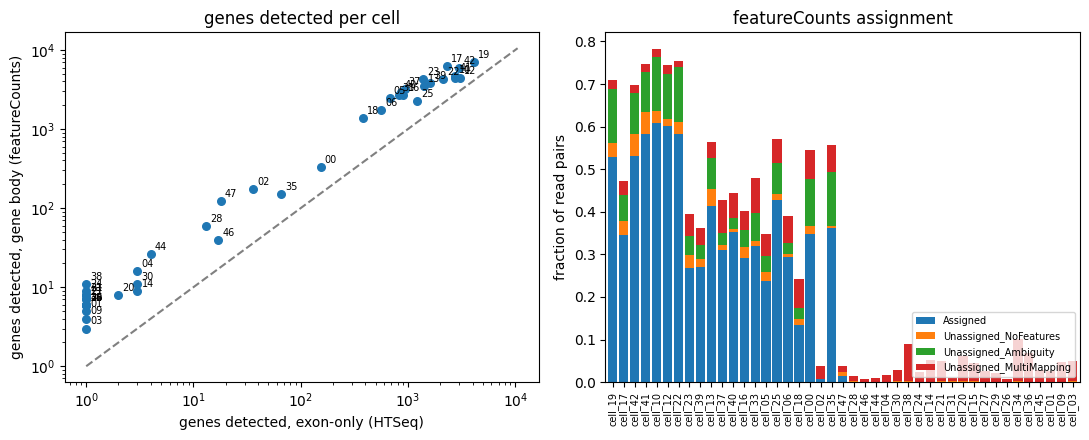

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# genes detected: exon-only vs gene body (points above the line = gain from introns)
ax = axes[0]
ax.scatter(compare["genes_exon"], compare["genes_genebody"], s=30)
for c, x, y in zip(compare.index, compare["genes_exon"], compare["genes_genebody"]):
    ax.annotate(c.replace("cell_", ""), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [1, compare[["genes_exon", "genes_genebody"]].max().max() * 1.5]
ax.plot(lim, lim, ls="--", c="grey")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("genes detected, exon-only (HTSeq)")
ax.set_ylabel("genes detected, gene body (featureCounts)")
ax.set_title("genes detected per cell")

# where the read pairs went
ax = axes[1]
cols = [c for c in ["Assigned", "Unassigned_NoFeatures", "Unassigned_Ambiguity", "Unassigned_MultiMapping"]
        if c in summary_frac.columns]
summary_frac.loc[compare.index, cols].plot.bar(stacked=True, ax=ax, width=0.85)
ax.set_ylabel("fraction of read pairs")
ax.set_title("featureCounts assignment")
ax.legend(fontsize=7, loc="lower right")
ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.show()

## 5. Next: use it in `02_RNA_DNA_QC.ipynb`

- load `counts_genebody.txt` as layer `genebody_counts` (same gene IDs as the other layers)
- MapMyCells: query with the gene-body counts instead of HTSeq
- complexity / mito QC: genes detected from `genebody_counts`; re-set `MIN_GENES` (numbers are ~2–4× higher)
- Salmon layers stay exon-only (Salmon maps to spliced transcripts and cannot use introns)